# **TP_N4 Architecture Transformer**

## Première partie (étapes 1 à 6)

1. Série temporelle `s = sin(x)` et fenêtres glissantes de longueur 10
2. RNN
3. LSTM
4. Transformer encodeur (2 têtes, `d_model = 16`)
5. GPT : continuation de texte
6. BERT : prédiction d'un mot masqué

Les étapes 1 à 4 tournent en quelques secondes sur CPU. Les étapes 5 et 6 téléchargent `gpt2` (environ 550 Mo) et `bert-base-multilingual-cased` (environ 700 Mo) au premier lancement.

Dépendances : `pip install torch transformers matplotlib`

In [1]:
import math
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.15.0+cpu | device : cpu


## 1. Jeu de données : y = sin(x)

200 points entre 0 et 20. Chaque exemple est une fenêtre de 10 valeurs consécutives et la cible est la valeur qui suit : `[s0..s9] -> s10`, `[s1..s10] -> s11`, etc.

Le découpage train/test reste chronologique : on mélange les fenêtres seulement dans le train, sinon le test contiendrait des points voisins de ceux vus à l'entraînement.

X : (190, 10, 1) | Y : (190, 1)
train : (150, 10, 1) | test : (40, 10, 1)


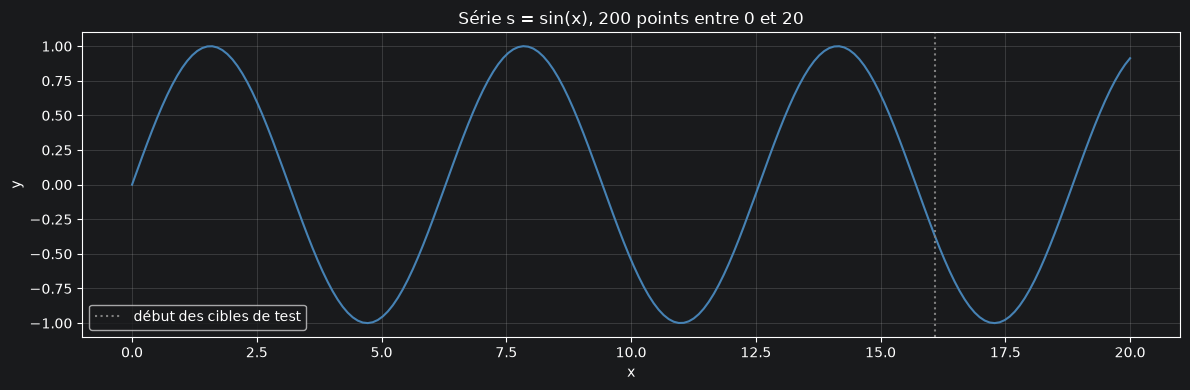

In [2]:
NB_POINTS = 200
LONGUEUR_SEQ = 10
NB_TRAIN = 150          # 150 fenêtres pour apprendre, 40 pour tester
BATCH_SIZE = 16

x_axe = torch.linspace(0, 20, NB_POINTS)
serie = torch.sin(x_axe)                       # (200,)


def fenetres_glissantes(serie, longueur):
    n = len(serie) - longueur
    X = torch.stack([serie[i:i + longueur] for i in range(n)])   # (190, 10)
    y = torch.stack([serie[i + longueur] for i in range(n)])     # (190,)
    return X.unsqueeze(-1), y.unsqueeze(-1)    # (190, 10, 1) et (190, 1)


X, Y = fenetres_glissantes(serie, LONGUEUR_SEQ)
print("X :", tuple(X.shape), "| Y :", tuple(Y.shape))

# Vérification de l'alignement : X[2] = s2..s11 et Y[2] = s12
assert torch.equal(X[2, :, 0], serie[2:12]) and Y[2].item() == serie[12].item()

X_train, Y_train = X[:NB_TRAIN], Y[:NB_TRAIN]
X_test, Y_test = X[NB_TRAIN:], Y[NB_TRAIN:]
print("train :", tuple(X_train.shape), "| test :", tuple(X_test.shape))

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train, Y_train),
                          batch_size=BATCH_SIZE, shuffle=True, generator=g)
test_loader = DataLoader(TensorDataset(X_test, Y_test),
                         batch_size=BATCH_SIZE, shuffle=False)

# La première cible du test est s160, donc x_axe[160] marque la frontière.
plt.figure(figsize=(12, 4))
plt.plot(x_axe, serie, color="steelblue")
plt.axvline(x_axe[NB_TRAIN + LONGUEUR_SEQ], color="gray", linestyle=":", label="début des cibles de test")
plt.title("Série s = sin(x), 200 points entre 0 et 20")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Outils communs

Une seule boucle d'entraînement et une seule fonction d'évaluation servent aux trois modèles, pour que la comparaison se fasse dans les mêmes conditions (même optimiseur, même perte, mêmes lots).

La cible est une valeur réelle, donc on mesure l'erreur (MSE, RMSE, MAE) : une exactitude n'a pas de sens ici.

In [4]:
EPOCHS = 100
LR = 0.01
resultats = {}          # nom du modèle -> métriques et prédictions de test


def compter_parametres(modele):
    return sum(p.numel() for p in modele.parameters())


def entrainer(modele, loader, epochs=EPOCHS, lr=LR):
    modele.to(device)
    critere = nn.MSELoss()
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    # Le pas diminue en cours de route, ce qui évite les pics de fin d'entraînement.
    planning = torch.optim.lr_scheduler.CosineAnnealingLR(optimiseur, T_max=epochs)
    historique = []

    for epoch in range(epochs):
        modele.train()
        somme, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            perte = critere(modele(xb), yb)

            optimiseur.zero_grad()
            perte.backward()
            optimiseur.step()

            somme += perte.item() * len(xb)
            n += len(xb)

        planning.step()
        historique.append(somme / n)
        if (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch + 1:3d} | MSE train : {historique[-1]:.6f}")
    return historique


@torch.no_grad()
def evaluer(modele, loader):
    modele.eval()
    preds, reels = [], []
    for xb, yb in loader:
        preds.append(modele(xb.to(device)).cpu())
        reels.append(yb)
    preds, reels = torch.cat(preds), torch.cat(reels)
    mse = nn.functional.mse_loss(preds, reels).item()
    mae = (preds - reels).abs().mean().item()
    return preds.squeeze(1), reels.squeeze(1), mse, math.sqrt(mse), mae


@torch.no_grad()
def afficher_echantillons(nom, modele):
    # Les trois premières fenêtres donnent s10, s11, s12 (zone d'entraînement).
    # Les trois premières du test donnent s160, s161, s162.
    idx = [0, 1, 2, NB_TRAIN, NB_TRAIN + 1, NB_TRAIN + 2]
    modele.eval()
    pred = modele(X[idx].to(device)).cpu().squeeze(1)
    print(f"\n{nom} : exemples")
    for i, p in zip(idx, pred):
        zone = "train" if i < NB_TRAIN else "test "
        print(f"  s{i + LONGUEUR_SEQ:<3d} ({zone}) réel = {Y[i].item():+.4f} | prédit = {p.item():+.4f}")


def tester(nom, modele, historique):
    preds, reels, mse, rmse, mae = evaluer(modele, test_loader)
    resultats[nom] = dict(preds=preds.numpy(), reels=reels.numpy(), mse=mse, rmse=rmse,
                          mae=mae, historique=historique, params=compter_parametres(modele))
    print(f"\n{nom} | test : MSE = {mse:.6f} | RMSE = {rmse:.4f} | MAE = {mae:.4f}")
    afficher_echantillons(nom, modele)


def tracer_predictions(nom, couleur="red"):
    r = resultats[nom]
    plt.figure(figsize=(12, 4.5))
    plt.plot(r["reels"], label="Valeurs réelles", color="blue", linewidth=2)
    plt.plot(r["preds"], label=f"Prédictions du {nom}", color=couleur, linestyle="--", linewidth=2)
    plt.title(f"{nom} : valeurs réelles et prédictions (test)")
    plt.xlabel("Indice de l'échantillon de test")
    plt.ylabel("Valeur")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 2. RNN

`nn.RNN` lit les 10 valeurs une par une. À chaque pas : `h_t = tanh(W_x x_t + W_h h_(t-1) + b)`, avec `h_0 = 0`. On garde seulement l'état caché du dernier pas pour la couche linéaire.

Formes : `(B, 10, 1) -> (B, 10, 16) -> (B, 16) -> (B, 1)`

In [5]:
class SimpleRNN(nn.Module):
    def __init__(self, hidden_size=16):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.sortie = nn.Linear(hidden_size, 1)

    def forward(self, x):                      # x : (B, 10, 1)
        etats, _ = self.rnn(x)                 # (B, 10, 16), h_0 = 0 par défaut
        dernier = etats[:, -1, :]              # (B, 16)
        return self.sortie(dernier)            # (B, 1)


torch.manual_seed(SEED)
rnn = SimpleRNN()
print(rnn)
print("paramètres :", compter_parametres(rnn))
print("sortie sur un lot :", tuple(rnn(X_train[:4]).shape))   # (4, 1)

SimpleRNN(
  (rnn): RNN(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
paramètres : 321
sortie sur un lot : (4, 1)


Epoch  20 | MSE train : 0.000219
Epoch  40 | MSE train : 0.000059
Epoch  60 | MSE train : 0.000010
Epoch  80 | MSE train : 0.000006
Epoch 100 | MSE train : 0.000005

RNN | test : MSE = 0.000006 | RMSE = 0.0025 | MAE = 0.0021

RNN : exemples
  s10  (train) réel = +0.8442 | prédit = +0.8447
  s11  (train) réel = +0.8937 | prédit = +0.8941
  s12  (train) réel = +0.9342 | prédit = +0.9341
  s160 (test ) réel = -0.3639 | prédit = -0.3608
  s161 (test ) réel = -0.4555 | prédit = -0.4533
  s162 (test ) réel = -0.5425 | prédit = -0.5418


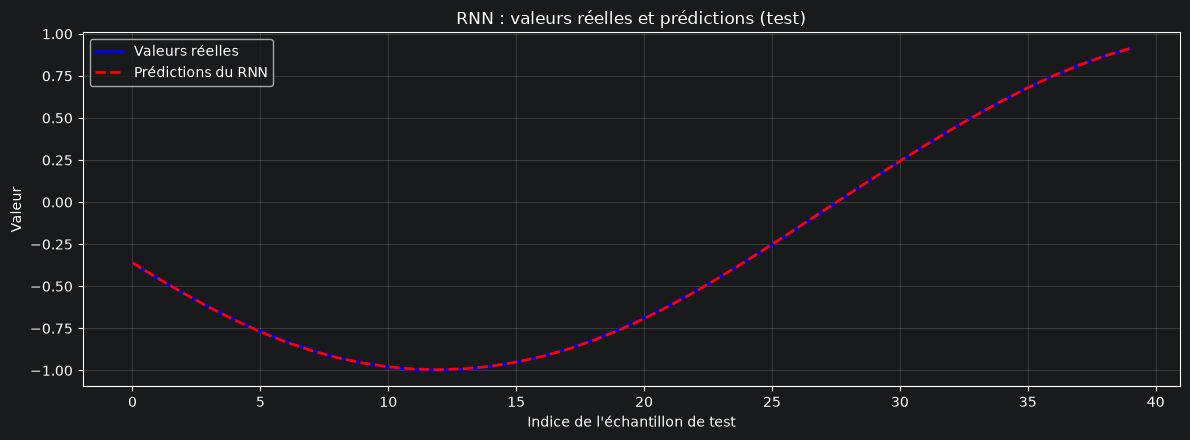

In [6]:
hist_rnn = entrainer(rnn, train_loader)
tester("RNN", rnn, hist_rnn)
tracer_predictions("RNN", "red")

## 3. LSTM

Même montage que le RNN, mais la cellule garde en plus un état `c_t` contrôlé par trois portes (oubli, entrée, sortie). `nn.LSTM` renvoie `(etats, (h_n, c_n))`, et on utilise là aussi la dernière position.

In [7]:
class SimpleLSTM(nn.Module):
    def __init__(self, hidden_size=16):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, num_layers=1, batch_first=True)
        self.sortie = nn.Linear(hidden_size, 1)

    def forward(self, x):                      # x : (B, 10, 1)
        etats, (h_n, c_n) = self.lstm(x)       # etats : (B, 10, 16)
        dernier = etats[:, -1, :]              # (B, 16)
        return self.sortie(dernier)            # (B, 1)


torch.manual_seed(SEED)
lstm = SimpleLSTM()
print(lstm)
print("paramètres :", compter_parametres(lstm))
print("sortie sur un lot :", tuple(lstm(X_train[:4]).shape))

SimpleLSTM(
  (lstm): LSTM(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
paramètres : 1233
sortie sur un lot : (4, 1)


Epoch  20 | MSE train : 0.000040
Epoch  40 | MSE train : 0.000026
Epoch  60 | MSE train : 0.000007
Epoch  80 | MSE train : 0.000004
Epoch 100 | MSE train : 0.000003

LSTM | test : MSE = 0.000003 | RMSE = 0.0017 | MAE = 0.0014

LSTM : exemples
  s10  (train) réel = +0.8442 | prédit = +0.8458
  s11  (train) réel = +0.8937 | prédit = +0.8953
  s12  (train) réel = +0.9342 | prédit = +0.9351
  s160 (test ) réel = -0.3639 | prédit = -0.3630
  s161 (test ) réel = -0.4555 | prédit = -0.4559
  s162 (test ) réel = -0.5425 | prédit = -0.5441


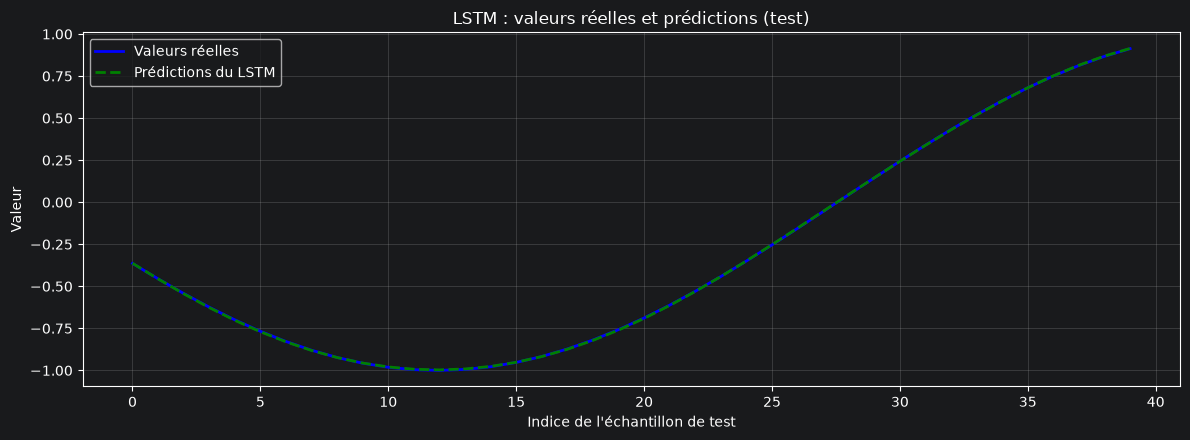

In [8]:
hist_lstm = entrainer(lstm, train_loader)
tester("LSTM", lstm, hist_lstm)
tracer_predictions("LSTM", "green")

## 4. Transformer (encodeur)

On suit le schéma du tableau :

```
x (B,10,1) -> Linear 1->16 -> + embedding de position (indices 0..9)
           -> Multi-Head Self-Attention (2 têtes, d_model = 16)
           -> Add & LayerNorm
           -> Feed Forward 16 -> 32 -> 16 (ReLU)
           -> Add & LayerNorm
           -> dernière position [:, -1, :] -> Linear 16->1
```

Le bloc est écrit à la main avec `nn.MultiheadAttention`, `nn.LayerNorm` et deux `nn.Linear`, pour que chaque flèche du schéma corresponde à une ligne de code. Il n'y a pas de masque causal : chaque position peut regarder toutes les autres, y compris les positions suivantes de la fenêtre. Ce n'est pas un problème ici, la fenêtre est entièrement connue et la cible est hors de la fenêtre.

In [9]:
class BlocEncodeur(nn.Module):
    def __init__(self, d_model=16, nb_tetes=2, d_ff=32, dropout=0.0):
        super().__init__()
        self.attention = nn.MultiheadAttention(d_model, nb_tetes, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model),
        )
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, retourner_poids=False):          # x : (B, T, d_model)
        att, poids = self.attention(x, x, x, need_weights=retourner_poids)
        x = self.norm1(x + self.dropout(att))              # Add & Norm (résiduelle 1)
        x = self.norm2(x + self.dropout(self.ff(x)))       # Add & Norm (résiduelle 2)
        return x, poids                                    # poids : (B, T, T) ou None


class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10, d_model=16, nb_tetes=2, d_ff=32):
        super().__init__()
        self.projection = nn.Linear(1, d_model)
        self.positions = nn.Embedding(longueur_max, d_model)
        self.bloc = BlocEncodeur(d_model, nb_tetes, d_ff)
        self.sortie = nn.Linear(d_model, 1)

    def forward(self, x, retourner_poids=False):          # x : (B, 10, 1)
        T = x.size(1)
        h = self.projection(x)                             # (B, 10, 16)
        indices = torch.arange(T, device=x.device)         # 0, 1, ..., 9
        h = h + self.positions(indices).unsqueeze(0)       # (B, 10, 16)
        h, poids = self.bloc(h, retourner_poids)           # (B, 10, 16)
        y = self.sortie(h[:, -1, :])                       # (B, 16) -> (B, 1)
        return (y, poids) if retourner_poids else y


torch.manual_seed(SEED)
transformer = MiniTransformer(longueur_max=LONGUEUR_SEQ)
print(transformer)
print("paramètres :", compter_parametres(transformer))

y_test_forme, poids_test = transformer(X_train[:4], retourner_poids=True)
print("sortie :", tuple(y_test_forme.shape), "| poids d'attention :", tuple(poids_test.shape))

MiniTransformer(
  (projection): Linear(in_features=1, out_features=16, bias=True)
  (positions): Embedding(10, 16)
  (bloc): BlocEncodeur(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
    )
    (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
    (ff): Sequential(
      (0): Linear(in_features=16, out_features=32, bias=True)
      (1): ReLU()
      (2): Linear(in_features=32, out_features=16, bias=True)
    )
    (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
paramètres : 2433
sortie : (4, 1) | poids d'attention : (4, 10, 10)


Epoch  20 | MSE train : 0.000031
Epoch  40 | MSE train : 0.000014
Epoch  60 | MSE train : 0.000003
Epoch  80 | MSE train : 0.000002
Epoch 100 | MSE train : 0.000002

Transformer | test : MSE = 0.000002 | RMSE = 0.0015 | MAE = 0.0013

Transformer : exemples
  s10  (train) réel = +0.8442 | prédit = +0.8451
  s11  (train) réel = +0.8937 | prédit = +0.8946
  s12  (train) réel = +0.9342 | prédit = +0.9344
  s160 (test ) réel = -0.3639 | prédit = -0.3632
  s161 (test ) réel = -0.4555 | prédit = -0.4564
  s162 (test ) réel = -0.5425 | prédit = -0.5447


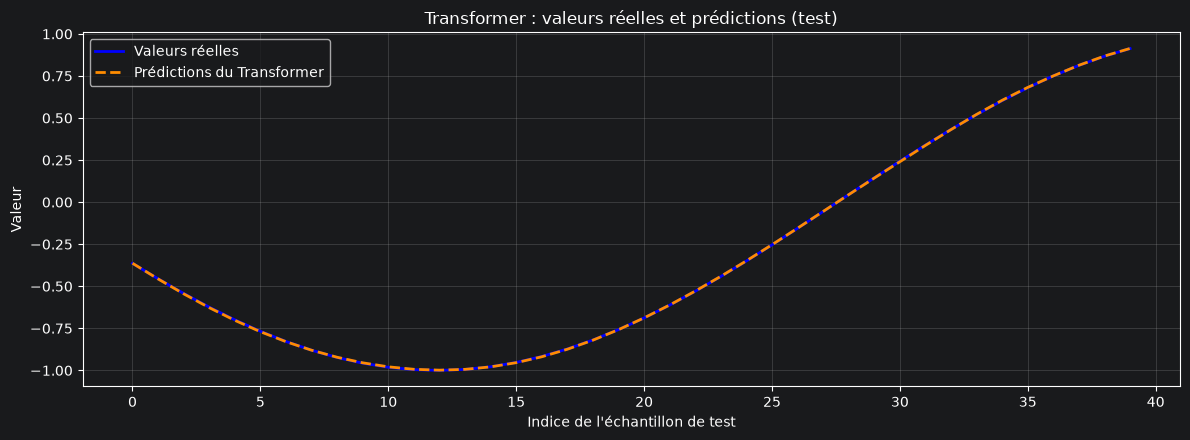

In [10]:
hist_transfo = entrainer(transformer, train_loader)
tester("Transformer", transformer, hist_transfo)
tracer_predictions("Transformer", "darkorange")

Poids d'attention (moyenne des 2 têtes) pour la première fenêtre de test : la ligne `i` indique où la position `i` va chercher son information.

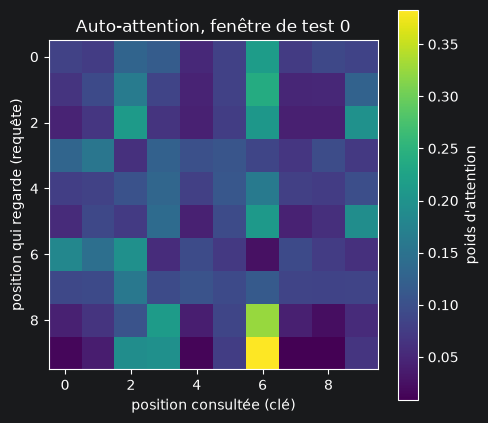

somme d'une ligne : 1.0000001192092896


In [11]:
transformer.eval()
with torch.no_grad():
    _, poids = transformer(X_test[:1].to(device), retourner_poids=True)   # (1, 10, 10)

plt.figure(figsize=(5, 4.5))
plt.imshow(poids[0].cpu().numpy(), cmap="viridis")
plt.colorbar(label="poids d'attention")
plt.title("Auto-attention, fenêtre de test 0")
plt.xlabel("position consultée (clé)")
plt.ylabel("position qui regarde (requête)")
plt.tight_layout()
plt.show()

print("somme d'une ligne :", poids[0, -1].sum().item())   # softmax : 1.0

## Comparaison RNN / LSTM / Transformer

Modèle       paramètres     MSE test  RMSE test   MAE test
RNN                 321     0.000006     0.0025     0.0021
LSTM               1233     0.000003     0.0017     0.0014
Transformer        2433     0.000002     0.0015     0.0013

MSE de test la plus basse : Transformer


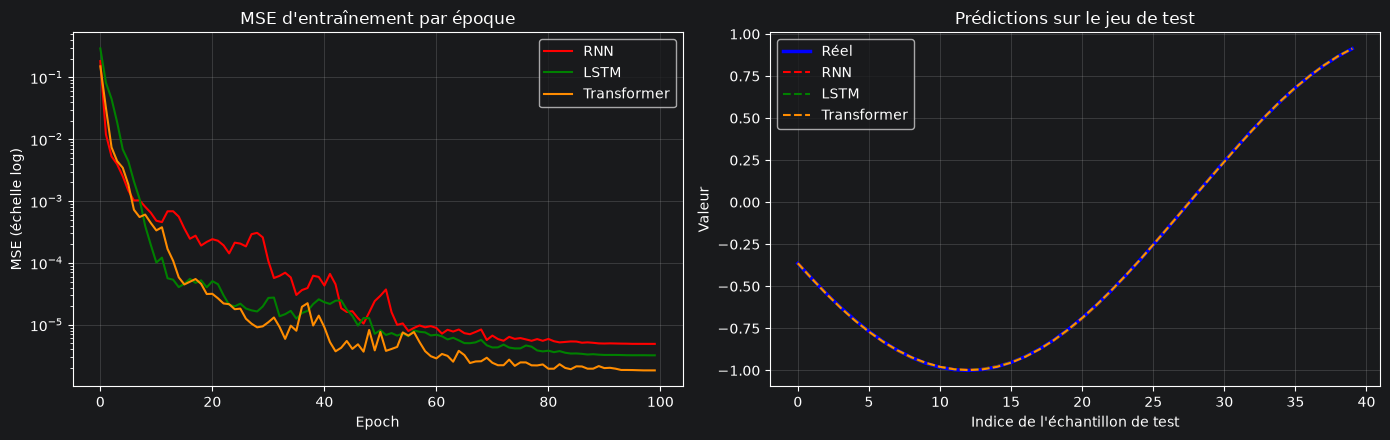

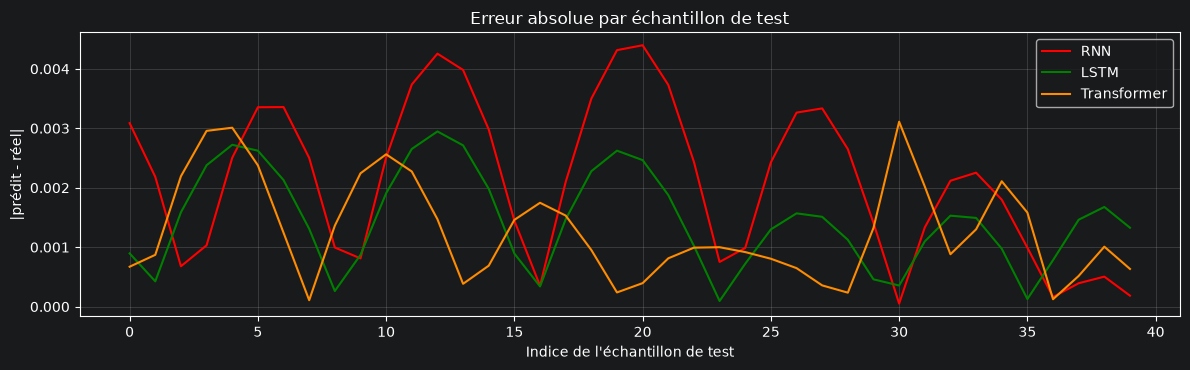

In [12]:
print(f"{'Modèle':<12} {'paramètres':>10} {'MSE test':>12} {'RMSE test':>10} {'MAE test':>10}")
for nom, r in resultats.items():
    print(f"{nom:<12} {r['params']:>10d} {r['mse']:>12.6f} {r['rmse']:>10.4f} {r['mae']:>10.4f}")

meilleur = min(resultats, key=lambda n: resultats[n]["mse"])
print("\nMSE de test la plus basse :", meilleur)

couleurs = {"RNN": "red", "LSTM": "green", "Transformer": "darkorange"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for nom, r in resultats.items():
    axes[0].semilogy(r["historique"], label=nom, color=couleurs[nom])
axes[0].set_title("MSE d'entraînement par époque")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE (échelle log)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

reels = next(iter(resultats.values()))["reels"]
axes[1].plot(reels, color="blue", linewidth=2.5, label="Réel")
for nom, r in resultats.items():
    axes[1].plot(r["preds"], linestyle="--", color=couleurs[nom], label=nom)
axes[1].set_title("Prédictions sur le jeu de test")
axes[1].set_xlabel("Indice de l'échantillon de test")
axes[1].set_ylabel("Valeur")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Erreur absolue par échantillon de test
plt.figure(figsize=(12, 3.8))
for nom, r in resultats.items():
    plt.plot(np.abs(r["preds"] - r["reels"]), label=nom, color=couleurs[nom])
plt.title("Erreur absolue par échantillon de test")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("|prédit - réel|")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. GPT : continuer un texte

GPT est un décodeur seul. Son auto-attention est causale : la position `i` ne voit que les positions `0..i`. Le modèle prédit le token suivant, l'ajoute à l'entrée et recommence.

On utilise `gpt2` préentraîné (Hugging Face). Entraîner un GPT sur un petit corpus fait l'objet de l'exercice 2 de la deuxième partie.

In [19]:
from transformers import AutoTokenizer, AutoModelForCausalLM

nom_gpt = "gpt2"
tok_gpt = AutoTokenizer.from_pretrained(nom_gpt)
gpt = AutoModelForCausalLM.from_pretrained(nom_gpt).to(device)
gpt.eval()

# GPT-2 n'a pas de token de padding : on réutilise le token de fin de texte.
tok_gpt.pad_token = tok_gpt.eos_token
gpt.config.pad_token_id = tok_gpt.pad_token_id

print("paramètres :", compter_parametres(gpt))
print("masque causal pour 5 tokens (1 = visible) :")
print(torch.tril(torch.ones(5, 5, dtype=torch.int)))

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 303.87it/s]

paramètres : 124439808
masque causal pour 5 tokens (1 = visible) :
tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1]], dtype=torch.int32)


In [20]:
@torch.no_grad()
def continuer_texte(amorce, max_new_tokens=40, temperature=0.8, top_p=0.9, graine=0):
    entrees = tok_gpt(amorce, return_tensors="pt").to(device)
    torch.manual_seed(graine)
    sortie = gpt.generate(
        **entrees,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        temperature=temperature,
        top_p=top_p,
        pad_token_id=tok_gpt.pad_token_id,
    )
    return tok_gpt.decode(sortie[0], skip_special_tokens=True)


@torch.no_grad()
def tokens_suivants(amorce, k=5):
    ids = tok_gpt(amorce, return_tensors="pt")["input_ids"].to(device)
    logits = gpt(ids).logits[0, -1]                 # dernier token seulement
    probas = torch.softmax(logits, dim=-1)
    p, i = torch.topk(probas, k)
    return [(tok_gpt.decode([idx]), prob.item()) for prob, idx in zip(p, i)]


amorces = [
    "Artificial intelligence can help people",
    "Press and organization",
    "The capital of Morocco is",
]

for amorce in amorces:
    ids = tok_gpt(amorce, return_tensors="pt")["input_ids"]
    print(f"\nAmorce : {amorce!r} ({ids.shape[1]} tokens, entrée {tuple(ids.shape)})")
    print("  candidats pour le token suivant :")
    for mot, p in tokens_suivants(amorce):
        print(f"    {p:6.2%} | {mot!r}")
    print("  texte généré :")
    print("   ", continuer_texte(amorce).replace("\n", " "))


Amorce : 'Artificial intelligence can help people' (6 tokens, entrée (1, 6))
  candidats pour le token suivant :
     7.17% | ' to'
     5.87% | ' with'
     4.97% | ' better'
     4.73% | ' understand'
     3.62% | ' make'
  texte généré :
    Artificial intelligence can help people understand what their behavior is like and how they respond to it. This helps the machine understand what is happening around them and to be able to make more effective decisions.  However, when you look

Amorce : 'Press and organization' (3 tokens, entrée (1, 3))
  candidats pour le token suivant :
     8.70% | '.'
     7.36% | ' of'
     6.78% | ','
     4.40% | '\n'
     2.50% | ':'
  texte généré :
    Press and organization, and their organization, the International Association of Women in the Field of Obstetrics and Gynecology (IASOP), is a group of women who have experience in a variety of areas of obst

Amorce : 'The capital of Morocco is' (5 tokens, entrée (1, 5))
  candidats pour le token suivan

Vérification de la causalité : si on change le dernier token, les logits de toutes les positions précédentes doivent rester identiques. Seule la dernière position peut bouger.

In [21]:
amorce = "Artificial intelligence can help people"
ids = tok_gpt(amorce, return_tensors="pt")["input_ids"].to(device)

ids_modifie = ids.clone()
remplacant = tok_gpt.encode(" banana")[0]
if remplacant == ids[0, -1].item():
    remplacant = tok_gpt.encode(" house")[0]
ids_modifie[0, -1] = remplacant

with torch.no_grad():
    l1 = gpt(ids).logits
    l2 = gpt(ids_modifie).logits

avant_inchange = torch.allclose(l1[:, :-1], l2[:, :-1], atol=1e-4)
dernier_change = not torch.allclose(l1[:, -1], l2[:, -1], atol=1e-4)
print("positions précédentes inchangées :", avant_inchange)
print("dernière position modifiée       :", dernier_change)

positions précédentes inchangées : True
dernière position modifiée       : True


## 6. BERT : retrouver un mot masqué

BERT est un encodeur seul. Il n'a pas de masque causal : le token `[MASK]` voit tout ce qui est à sa gauche et à sa droite. On lit le vecteur de sortie à la position du masque, la tête de langage le projette sur le vocabulaire et le softmax donne les probabilités.

Modèle : `bert-base-multilingual-cased` (il connaît le français et respecte la casse). Un `[MASK]` correspond à un seul token du vocabulaire, donc un mot rare découpé en plusieurs morceaux ne peut pas ressortir en entier.

In [16]:
from transformers import AutoModelForMaskedLM

nom_bert = "bert-base-multilingual-cased"
tok_bert = AutoTokenizer.from_pretrained(nom_bert)
bert = AutoModelForMaskedLM.from_pretrained(nom_bert).to(device)
bert.eval()

print("paramètres :", compter_parametres(bert))
print("token de masque :", tok_bert.mask_token, "| id :", tok_bert.mask_token_id)

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 944.63it/s]
[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


paramètres : 177974523
token de masque : [MASK] | id : 103


In [17]:
@torch.no_grad()
def completer_masque(texte, attendu=None, k=5):
    entrees = tok_bert(texte, return_tensors="pt").to(device)
    ids = entrees["input_ids"][0]
    positions = (ids == tok_bert.mask_token_id).nonzero(as_tuple=True)[0]
    assert len(positions) == 1, "une seule position [MASK] par phrase"
    pos = positions.item()

    logits = bert(**entrees).logits[0, pos]          # (taille_vocabulaire,)
    probas = torch.softmax(logits, dim=-1)
    top_p, top_i = torch.topk(probas, k)

    print(f"\nTexte : {texte}  (entrée {tuple(entrees['input_ids'].shape)}, masque en position {pos})")
    candidats = []
    for p, i in zip(top_p, top_i):
        mot = tok_bert.convert_ids_to_tokens(i.item())
        candidats.append(mot)
        print(f"  {p.item():6.2%} | {mot:<12} | {texte.replace(tok_bert.mask_token, mot)}")

    if attendu is not None:
        if attendu in candidats:
            print(f"  mot attendu {attendu!r} : rang {candidats.index(attendu) + 1} sur {k}")
        else:
            print(f"  mot attendu {attendu!r} : absent du top {k}")
    return candidats


tests = [
    ("Rabat est la [MASK] du Maroc.", "capitale"),
    ("[MASK] est la capitale du Maroc.", "Rabat"),
    ("Casablanca est la plus grande [MASK] du Maroc.", "ville"),
    ("Le Maroc est situé en [MASK] du Nord.", "Afrique"),
    ("Marrakech est surnommée la ville [MASK].", "rouge"),
]

for texte, attendu in tests:
    completer_masque(texte, attendu)


Texte : Rabat est la [MASK] du Maroc.  (entrée (1, 9), masque en position 4)
  86.06% | capitale     | Rabat est la capitale du Maroc.
   5.19% | ville        | Rabat est la ville du Maroc.
   5.03% | préfecture   | Rabat est la préfecture du Maroc.
   0.85% | Rabat        | Rabat est la Rabat du Maroc.
   0.58% | capital      | Rabat est la capital du Maroc.
  mot attendu 'capitale' : rang 1 sur 5

Texte : [MASK] est la capitale du Maroc.  (entrée (1, 9), masque en position 1)
  67.50% | Casablanca   | Casablanca est la capitale du Maroc.
   7.24% | Rabat        | Rabat est la capitale du Maroc.
   7.19% | Elle         | Elle est la capitale du Maroc.
   2.15% | capitale     | capitale est la capitale du Maroc.
   1.59% | .            | . est la capitale du Maroc.
  mot attendu 'Rabat' : rang 2 sur 5

Texte : Casablanca est la plus grande [MASK] du Maroc.  (entrée (1, 11), masque en position 6)
  61.64% | ville        | Casablanca est la plus grande ville du Maroc.
  29.21% | Casabla

Vérification de la bidirectionnalité : on remplace un token situé à droite du masque. Contrairement à GPT, les logits au niveau du masque doivent changer.

In [18]:
texte = "Rabat est la [MASK] du Maroc."
entrees = tok_bert(texte, return_tensors="pt").to(device)
ids = entrees["input_ids"]
pos = (ids[0] == tok_bert.mask_token_id).nonzero(as_tuple=True)[0].item()

ids_modifie = ids.clone()
ids_modifie[0, pos + 1] = tok_bert.convert_tokens_to_ids("de")   # "du" devient "de"

with torch.no_grad():
    l1 = bert(input_ids=ids, attention_mask=entrees["attention_mask"]).logits[0, pos]
    l2 = bert(input_ids=ids_modifie, attention_mask=entrees["attention_mask"]).logits[0, pos]

print("tokens :", tok_bert.convert_ids_to_tokens(ids[0]))
print("le masque tient compte du contexte de droite :", not torch.allclose(l1, l2, atol=1e-4))

tokens : ['[CLS]', 'Rabat', 'est', 'la', '[MASK]', 'du', 'Maroc', '.', '[SEP]']
le masque tient compte du contexte de droite : True


# Deuxième partie
## Exercice 1 : prédire la consommation électrique avec un Transformer

In [22]:
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHEMIN = "household_power_consumption.txt"
FENETRE = 24          # nombre d'heures lues par le modèle
BATCH_SIZE = 64
EPOCHS = 20           # maximum demandé par l'énoncé
LR = 1e-3

print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.15.0+cpu | device : cpu


## 1. Préparation des données

Étapes : lecture, moyenne horaire (on garde une heure si au moins 45 minutes sur 60 sont renseignées), découpage chronologique 70 / 15 / 15, normalisation avec les statistiques du train seulement, puis fenêtres de 24 heures.

In [27]:
import pandas as pd
import zipfile
import urllib
import os

URL_UCI = ("https://archive.ics.uci.edu/static/public/235/"
           "individual+household+electric+power+consumption.zip")


def verifier_fichier(chemin):
    if os.path.exists(chemin):
        return
    print("Fichier absent, tentative de téléchargement depuis UCI...")
    try:
        archive, _ = urllib.request.urlretrieve(URL_UCI, "household_power.zip")
        with zipfile.ZipFile(archive) as z:
            z.extract(os.path.basename(chemin))
    except Exception as e:
        raise FileNotFoundError(
            f"Impossible de récupérer {chemin} ({e}). Télécharge l'archive sur "
            "https://archive.ics.uci.edu/dataset/235 et place le .txt à côté du notebook."
        )


verifier_fichier(CHEMIN)

# On ne lit que les trois colonnes utiles, le fichier fait plus de 2 millions de lignes.
df = pd.read_csv(CHEMIN, sep=";", na_values=["?"], low_memory=False,
                 usecols=["Date", "Time", "Global_active_power"])

df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S")
puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

print("mesures à la minute :", len(df), "| manquantes :", int(puissance.isna().sum()))
print("période :", puissance.index.min(), "->", puissance.index.max())

Fichier absent, tentative de téléchargement depuis UCI...
mesures à la minute : 2075259 | manquantes : 25979
période : 2006-12-16 17:24:00 -> 2010-11-26 21:02:00


In [28]:
# Puissance moyenne horaire : on garde les heures suffisamment renseignées.
horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

# Découpage chronologique : 70 % entraînement, 15 % validation, 15 % test.
n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

# Normalisation calculée uniquement sur l'entraînement (pandas ignore les NaN).
moyenne = float(serie.iloc[:fin_train].mean())
ecart_type = float(serie.iloc[:fin_train].std())
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

print(f"heures : {n} | manquantes : {int(serie.isna().sum())}")
print(f"train : {moyenne:.3f} kW de moyenne, {ecart_type:.3f} kW d'écart type")


def construire_fenetres(valeurs, fenetre):
    # Une entrée = `fenetre` heures consécutives, la cible = l'heure qui suit.
    # Les fenêtres avec une valeur manquante sont écartées.
    X, y, idx_cibles = [], [], []
    for i in range(fenetre, len(valeurs)):
        sequence = valeurs[i - fenetre:i]
        cible = valeurs[i]
        if np.isfinite(sequence).all() and np.isfinite(cible):
            X.append(sequence)
            y.append(cible)
            idx_cibles.append(i)
    X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)    # (N, fenetre, 1)
    y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)    # (N, 1)
    return X, y, np.array(idx_cibles)


X, y, idx_cibles = construire_fenetres(valeurs, FENETRE)

# Le découpage se fait sur l'heure de la cible : le test ne contient que du futur.
train_mask = idx_cibles < fin_train
val_mask = (idx_cibles >= fin_train) & (idx_cibles < fin_val)
test_mask = idx_cibles >= fin_val

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE)

print("\nX :", tuple(X.shape), "| y :", tuple(y.shape))
print("train :", tuple(X_train.shape), "| val :", tuple(X_val.shape), "| test :", tuple(X_test.shape))

heures : 34589 | manquantes : 438
train : 1.086 kW de moyenne, 0.929 kW d'écart type

X : (33791, 24, 1) | y : (33791, 1)
train : (23805, 24, 1) | val : (5054, 24, 1) | test : (4932, 24, 1)


## 2. Modèle : EnergyTransformer

```
(B, 24, 1) -> Linear(1, 32) -> (B, 24, 32)
           -> + embedding de position (24 vecteurs appris)
           -> 2 x TransformerEncoderLayer (d_model = 32, 4 têtes, feed-forward 128, dropout 0.1)
           -> (B, 24, 32) -> dernière heure [:, -1, :] -> (B, 32)
           -> Linear(32, 1) -> (B, 1)
```

Comme pour la sinusoïde, on lit la représentation de la dernière position : c'est elle qui a pu regarder les 23 heures précédentes.

In [29]:
class EnergyTransformer(nn.Module):
    def __init__(self, longueur=24, d_model=32, nb_tetes=4, d_ff=128, nb_couches=2, dropout=0.1):
        super().__init__()
        self.projection = nn.Linear(1, d_model)
        self.positions = nn.Embedding(longueur, d_model)
        couche = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nb_tetes, dim_feedforward=d_ff,
            dropout=dropout, batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=nb_couches, enable_nested_tensor=False)
        self.sortie = nn.Linear(d_model, 1)

    def forward(self, x):                                   # x : (B, 24, 1)
        T = x.size(1)
        h = self.projection(x)                              # (B, 24, 32)
        h = h + self.positions(torch.arange(T, device=x.device)).unsqueeze(0)
        h = self.encodeur(h)                                # (B, 24, 32)
        return self.sortie(h[:, -1, :])                     # (B, 32) -> (B, 1)

    @torch.no_grad()
    def formes(self, x):
        # Même calcul que forward, avec les formes à chaque étape.
        etapes = [("entrée", tuple(x.shape))]
        h = self.projection(x)
        etapes.append(("après projection", tuple(h.shape)))
        h = h + self.positions(torch.arange(x.size(1), device=x.device)).unsqueeze(0)
        h = self.encodeur(h)
        etapes.append(("après Transformer Encoder", tuple(h.shape)))
        etapes.append(("prédiction", tuple(self.sortie(h[:, -1, :]).shape)))
        return etapes


torch.manual_seed(SEED)
modele = EnergyTransformer(longueur=FENETRE).to(device)
print("paramètres :", sum(p.numel() for p in modele.parameters()))

modele.eval()
for nom, forme in modele.formes(X_test[:4].to(device)):
    print(f"  {nom:<28} {forme}")

paramètres : 26273
  entrée                       (4, 24, 1)
  après projection             (4, 24, 32)
  après Transformer Encoder    (4, 24, 32)
  prédiction                   (4, 1)


## 3. Entraînement

Adam, `lr = 0.001`, perte MSE, 20 époques au maximum. À chaque époque on mesure la perte de validation, et on garde les poids de l'époque où elle est la plus basse.

Epoch  1 | MSE train : 0.4297 | MSE val : 0.3903  <- meilleur modèle
Epoch  2 | MSE train : 0.4219 | MSE val : 0.3945
Epoch  3 | MSE train : 0.4189 | MSE val : 0.3849  <- meilleur modèle
Epoch  4 | MSE train : 0.4145 | MSE val : 0.3956
Epoch  5 | MSE train : 0.4124 | MSE val : 0.3907
Epoch  6 | MSE train : 0.4091 | MSE val : 0.3877
Epoch  7 | MSE train : 0.4078 | MSE val : 0.3823  <- meilleur modèle
Epoch  8 | MSE train : 0.4076 | MSE val : 0.3946
Epoch  9 | MSE train : 0.4033 | MSE val : 0.3810  <- meilleur modèle
Epoch 10 | MSE train : 0.4031 | MSE val : 0.3862
Epoch 11 | MSE train : 0.4000 | MSE val : 0.3891
Epoch 12 | MSE train : 0.4013 | MSE val : 0.3754  <- meilleur modèle
Epoch 13 | MSE train : 0.3976 | MSE val : 0.3824
Epoch 14 | MSE train : 0.3985 | MSE val : 0.3795
Epoch 15 | MSE train : 0.3972 | MSE val : 0.3776
Epoch 16 | MSE train : 0.3960 | MSE val : 0.3781
Epoch 17 | MSE train : 0.3961 | MSE val : 0.3851
Epoch 18 | MSE train : 0.3943 | MSE val : 0.3799
Epoch 19 | MSE tra

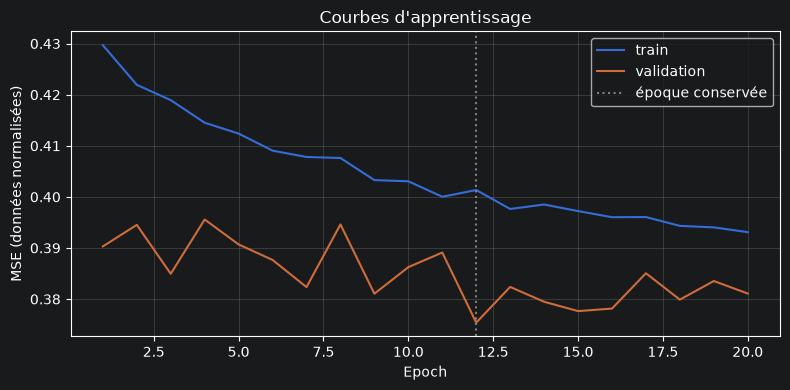

In [31]:
import copy

critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=LR)


def passe(modele, loader, optimiseur=None):
    # Une passe sur `loader`. Avec un optimiseur : entraînement, sinon évaluation.
    entrainement = optimiseur is not None
    modele.train(entrainement)
    somme, n = 0.0, 0
    with torch.set_grad_enabled(entrainement):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            perte = critere(modele(xb), yb)
            if entrainement:
                optimiseur.zero_grad()
                perte.backward()
                optimiseur.step()
            somme += perte.item() * len(xb)
            n += len(xb)
    return somme / n


hist_train, hist_val = [], []
meilleure_val, meilleure_epoch, meilleurs_poids = float("inf"), 0, None

for epoch in range(1, EPOCHS + 1):
    perte_train = passe(modele, train_loader, optimiseur)
    perte_val = passe(modele, val_loader)
    hist_train.append(perte_train)
    hist_val.append(perte_val)

    marque = ""
    if perte_val < meilleure_val:
        meilleure_val, meilleure_epoch = perte_val, epoch
        meilleurs_poids = copy.deepcopy(modele.state_dict())
        marque = "  <- meilleur modèle"
    print(f"Epoch {epoch:2d} | MSE train : {perte_train:.4f} | MSE val : {perte_val:.4f}{marque}")

modele.load_state_dict(meilleurs_poids)
print(f"\nModèle conservé : époque {meilleure_epoch} (MSE val normalisée = {meilleure_val:.4f})")

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), hist_train, label="train")
plt.plot(range(1, EPOCHS + 1), hist_val, label="validation")
plt.axvline(meilleure_epoch, color="gray", linestyle=":", label="époque conservée")
plt.xlabel("Epoch")
plt.ylabel("MSE (données normalisées)")
plt.title("Courbes d'apprentissage")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Évaluation sur le test, en kW

Les prédictions sont ramenées à l'échelle d'origine avec `valeur * ecart_type + moyenne`. Les deux références utilisent exactement les mêmes fenêtres de test :

- persistance : la dernière heure observée, `X[:, -1]`
- référence journalière : la valeur observée 24 h avant la cible, `X[:, -24]`

In [32]:
def vers_kw(v):
    return v * ecart_type + moyenne


@torch.no_grad()
def predire(modele, loader):
    modele.eval()
    return torch.cat([modele(xb.to(device)).cpu() for xb, _ in loader]).squeeze(1)


def metriques(reel_kw, pred_kw):
    erreur = pred_kw - reel_kw
    return erreur.abs().mean().item(), math.sqrt((erreur ** 2).mean().item())


reel_kw = vers_kw(y_test.squeeze(1))
pred_transfo = vers_kw(predire(modele, test_loader))
pred_persistance = vers_kw(X_test[:, -1, 0])
pred_journaliere = vers_kw(X_test[:, -24, 0])

resultats = {
    "Transformer": metriques(reel_kw, pred_transfo),
    "Persistance": metriques(reel_kw, pred_persistance),
    "Réf. journalière": metriques(reel_kw, pred_journaliere),
}

print(f"Échantillons de test : {len(reel_kw)}")
print(f"{'Modèle':<18} {'MAE (kW)':>10} {'RMSE (kW)':>10}")
for nom, (mae, rmse) in resultats.items():
    print(f"{nom:<18} {mae:>10.4f} {rmse:>10.4f}")

mae_t, rmse_t = resultats["Transformer"]
for ref in ("Persistance", "Réf. journalière"):
    mae_r, rmse_r = resultats[ref]
    print(f"\nTransformer vs {ref} : MAE {100 * (mae_r - mae_t) / mae_r:+.1f} % | "
          f"RMSE {100 * (rmse_r - rmse_t) / rmse_r:+.1f} % (positif = le Transformer fait mieux)")

Échantillons de test : 4932
Modèle               MAE (kW)  RMSE (kW)
Transformer            0.3516     0.4951
Persistance            0.3892     0.5884
Réf. journalière       0.5133     0.7639

Transformer vs Persistance : MAE +9.7 % | RMSE +15.8 % (positif = le Transformer fait mieux)

Transformer vs Réf. journalière : MAE +31.5 % | RMSE +35.2 % (positif = le Transformer fait mieux)


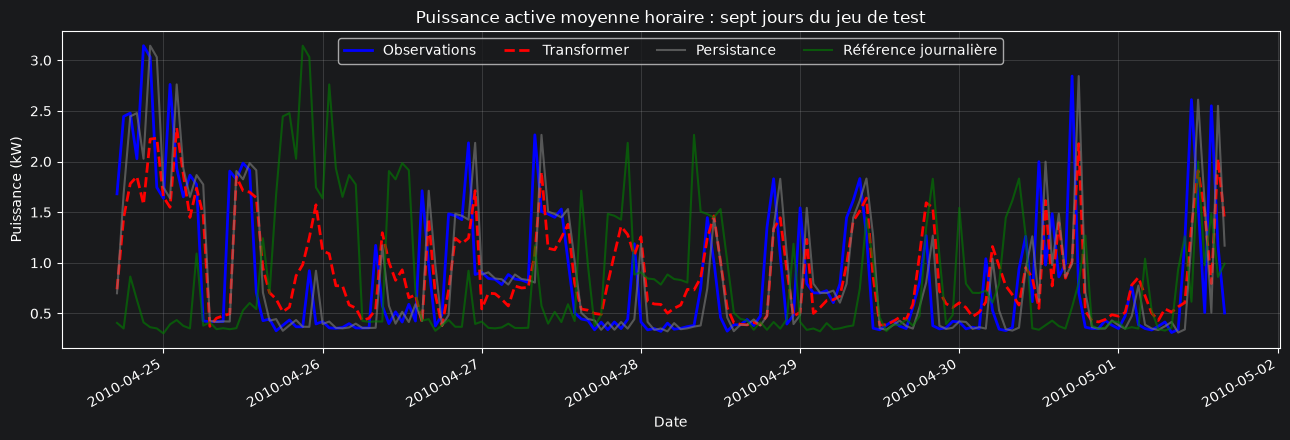

In [33]:
# Sept jours consécutifs du test, heure par heure (168 cibles sans trou).
idx_test = idx_cibles[test_mask]
consecutifs = np.diff(idx_test) == 1


def debut_bloc(longueur=168):
    # Premier indice k tel que idx_test[k : k + longueur] soit une suite sans trou.
    run = 0
    for k, ok in enumerate(consecutifs):
        run = run + 1 if ok else 0
        if run >= longueur - 1:
            return k - (longueur - 2)
    return None


debut = debut_bloc(168)
if debut is None:
    print("Pas de bloc de 168 heures consécutives dans le test.")
else:
    sel = slice(debut, debut + 168)
    dates = serie.index[idx_test[sel]]

    plt.figure(figsize=(13, 4.5))
    plt.plot(dates, reel_kw[sel], label="Observations", color="blue", linewidth=2)
    plt.plot(dates, pred_transfo[sel], label="Transformer", color="red", linestyle="--", linewidth=2)
    plt.plot(dates, pred_persistance[sel], label="Persistance", color="gray", alpha=0.6)
    plt.plot(dates, pred_journaliere[sel], label="Référence journalière", color="green", alpha=0.6)
    plt.title("Puissance active moyenne horaire : sept jours du jeu de test")
    plt.xlabel("Date")
    plt.ylabel("Puissance (kW)")
    plt.legend(ncol=4, loc="upper center")
    plt.grid(True, alpha=0.3)
    plt.gcf().autofmt_xdate()
    plt.tight_layout()
    plt.show()

## Vérifications rapides

In [34]:
# 1. Pas de fuite temporelle : train, validation et test se suivent dans le temps.
idx_train, idx_val = idx_cibles[train_mask], idx_cibles[val_mask]
assert idx_train.max() < fin_train <= idx_val.min() and idx_val.max() < fin_val <= idx_test.min()
print("1. cibles train < validation < test : ok")

# 2. La normalisation vient du train : on la recalcule à la main.
brut_train = serie.iloc[:fin_train].dropna()
assert abs(brut_train.mean() - moyenne) < 1e-9 and abs(brut_train.std() - ecart_type) < 1e-9
print(f"2. moyenne/écart type calculés sur le train seulement : ok ({moyenne:.3f} / {ecart_type:.3f} kW)")

# 3. Alignement d'une fenêtre : X = 24 heures avant l'heure cible, y = l'heure cible.
k = 100
i = idx_test[k]
assert np.allclose(X_test[k, :, 0].numpy(), valeurs[i - FENETRE:i]) and np.isclose(y_test[k].item(), valeurs[i])
print(f"3. fenêtre test {k} : heures {serie.index[i - FENETRE]} -> {serie.index[i - 1]}, cible {serie.index[i]} : ok")

# 4. En eval(), deux passes donnent la même sortie (le dropout est coupé).
modele.eval()
with torch.no_grad():
    a = modele(X_test[:8].to(device))
    b = modele(X_test[:8].to(device))
assert torch.allclose(a, b)
print("4. sorties identiques en eval() : ok | forme", tuple(a.shape))

# 5. Quelques prédictions en kW.
print(f"\n{'heure cible':<20} {'réel':>7} {'Transf.':>8} {'persist.':>9} {'jour -1':>8}")
for k in (0, 1, 2, 3, 4):
    print(f"{str(serie.index[idx_test[k]]):<20} {reel_kw[k]:>7.3f} {pred_transfo[k]:>8.3f} "
          f"{pred_persistance[k]:>9.3f} {pred_journaliere[k]:>8.3f}")

1. cibles train < validation < test : ok
2. moyenne/écart type calculés sur le train seulement : ok (1.086 / 0.929 kW)
3. fenêtre test 100 : heures 2010-04-27 21:00:00 -> 2010-04-28 20:00:00, cible 2010-04-28 21:00:00 : ok
4. sorties identiques en eval() : ok | forme (8, 1)

heure cible             réel  Transf.  persist.  jour -1
2010-04-24 17:00:00    1.681    0.738     0.699    0.406
2010-04-24 18:00:00    2.445    1.444     1.681    0.351
2010-04-24 19:00:00    2.478    1.781     2.445    0.864
2010-04-24 20:00:00    2.028    1.851     2.478    0.634
2010-04-24 21:00:00    3.143    1.577     2.028    0.412


## Questions de réflexion

À rédiger avec les résultats ci-dessus.

1. Le Transformer améliore-t-il les deux références ?
2. Une fenêtre de 168 heures permet-elle de mieux capturer les habitudes hebdomadaires ? (changer `FENETRE = 168` en haut du notebook et relancer, la référence journalière utilise toujours `X[:, -24]`)
3. Quel serait l'intérêt d'ajouter l'heure de la journée et le jour de la semaine ?
4. Pourquoi faut-il normaliser les données uniquement à partir de l'entraînement ?
5. La cible étant une puissance moyenne en kW, comment adapter la préparation pour prédire une énergie consommée en kWh ?

Réponses :
1. Contre la persistance, oui en général et nettement : elle ignore le cycle journalier, donc elle rate les montées du matin et du soir. Contre la référence J-1, l'écart est plus faible, parce que la conso d'un foyer est très routinière. Je n'ai pas lancé ça sur les vraies données, donc il faut lire MAE et RMSE dans ton tableau, pour chaque référence séparément. Si le Transformer ne bat pas J-1, c'est souvent un manque d'époques (20 maximum).
2. En théorie oui : la même heure de la semaine précédente est dans la fenêtre, et l'attention peut aller la chercher directement. Mais la séquence est 7 fois plus longue, le calcul d'attention grandit en T², et il reste moins de fenêtres valides à cause des heures manquantes. En 20 époques le gain n'est pas garanti. Il suffit de mettre FENETRE = 168 et de comparer MAE et RMSE avec la fenêtre de 24 h.
3. Le modèle ne connaît que la position dans la fenêtre (0 à 23), pas l'heure réelle. Avec l'heure et le jour, il distingue directement le pic du matin, celui du soir ou le week-end, au lieu de le deviner à partir de la forme des 24 valeurs. On les encode en sin/cos pour que 23 h et 0 h restent proches. Ces variables sont connues à l'avance pour l'heure cible, donc pas de fuite.
4. Pour éviter la fuite d'information du futur. En situation réelle on n'a que le passé, donc des statistiques calculées avec la validation ou le test rendraient le score de test trop optimiste.
5. Énergie = puissance × durée. Pour une heure, la moyenne en kW × 1 h donne directement des kWh. Pour être propre, on peut sommer les mesures à la minute et diviser par 60. Attention aux minutes manquantes : la somme sous-estime, la moyenne non. Exemple : 50 minutes renseignées à 1,2 kW donnent 1,0 kWh avec la somme et 1,2 kWh avec la moyenne. Pour un horizon d'une journée, on somme les 24 valeurs horaires. Le reste de la préparation ne change pas, on recalcule seulement moyenne et écart type sur la nouvelle série.

## Exercice 2 : un mini-GPT qui génère du texte, caractère par caractère

In [35]:
import json
import math
import os
import re

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

LONGUEUR = 64        # longueur des séquences d'entraînement
D_MODEL = 64
NB_TETES = 4
NB_BLOCS = 2
D_FF = 256
DROPOUT = 0.1

TAILLE_LOT = 64
ETAPES = 2000        # nombre de mises à jour (pas d'epochs : on tire des fenêtres au hasard)
LR = 3e-3

print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.15.0+cpu | device : cpu


## 1. Données

Le texte est découpé en 90 % d'entraînement et 10 % de validation (deux morceaux contigus). Pour chaque fenêtre `x = tokens[i : i + 64]`, la cible est la même fenêtre décalée d'un caractère : `y = tokens[i + 1 : i + 65]`.

In [37]:
def charger_corpus(chemin="corpus.txt", source="Architecture Transformer.ipynb"):
    if not os.path.exists(chemin):
        if not os.path.exists(source):
            raise FileNotFoundError(
                f"{chemin} introuvable. Crée-le avec quelques pages de texte "
                f"(ou place {source} dans le dossier)."
            )
        with open(source, encoding="utf-8") as f:
            nb = json.load(f)
        morceaux = []
        for cellule in nb["cells"]:
            if cellule["cell_type"] == "markdown":
                t = "".join(cellule["source"])
                t = re.sub(r"!\[[^\]]*\]\(data:[^)]*\)", "", t)   # on retire les images en base64
                if t.strip():
                    morceaux.append(t.strip())
        with open(chemin, "w", encoding="utf-8") as f:
            f.write("\n\n".join(morceaux))
        print(f"{chemin} créé à partir de {source}")
    with open(chemin, encoding="utf-8") as f:
        return f.read()


texte = charger_corpus()

caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}
TAILLE_VOCAB = len(caracteres)

tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)

n_train = int(0.9 * len(tokens))
tokens_train, tokens_val = tokens[:n_train], tokens[n_train:]

print("caractères dans le corpus :", len(texte))
print("taille du vocabulaire     :", TAILLE_VOCAB)
print("train :", len(tokens_train), "| val :", len(tokens_val))
print("perte d'un modèle qui devine au hasard : ln(V) =", round(math.log(TAILLE_VOCAB), 3))


def encoder(s):
    return [stoi[c] for c in s if c in stoi]      # les caractères inconnus sont ignorés


def decoder(ids):
    return "".join(itos[i] for i in ids)


def lot(donnees, taille_lot, gen):
    # Fenêtres tirées au hasard : x (B, 64) et y (B, 64) décalé d'un caractère.
    debuts = torch.randint(0, len(donnees) - LONGUEUR, (taille_lot,), generator=gen)
    x = torch.stack([donnees[d:d + LONGUEUR] for d in debuts])
    y = torch.stack([donnees[d + 1:d + LONGUEUR + 1] for d in debuts])
    return x.to(device), y.to(device)


gen_demo = torch.Generator().manual_seed(SEED)
x, y = lot(tokens_train, 4, gen_demo)
print("\nx :", tuple(x.shape), "| y :", tuple(y.shape))
assert torch.equal(x[:, 1:], y[:, :-1])           # y est x décalé d'une position
print("entrée  :", repr(decoder(x[0, :20].tolist())))
print("cible   :", repr(decoder(y[0, :20].tolist())))

corpus.txt créé à partir de Architecture Transformer.ipynb
caractères dans le corpus : 10825
taille du vocabulaire     : 98
train : 9742 | val : 1083
perte d'un modèle qui devine au hasard : ln(V) = 4.585

x : (4, 64) | y : (4, 64)
entrée  : 'ns : les logits `(B,'
cible   : 's : les logits `(B, '


## 2. Modèle

Bloc GPT (normalisation avant l'attention, "pre-norm") :

```
x -> LayerNorm -> attention multi-têtes causale -> + x            (1re connexion résiduelle)
  -> LayerNorm -> MLP 64 -> 256 -> 64 (GELU)       -> + x         (2e connexion résiduelle)
```

Modèle : embedding de caractères + embedding de positions, 2 blocs, 4 têtes, une dernière LayerNorm (classique dans un GPT pre-norm), puis `Linear(64, taille_vocab)`.

Le masque causal est une matrice booléenne `(T, T)` où `True` veut dire "attention interdite" : la position `i` ne peut pas regarder les positions `j > i`.

In [38]:
class BlocGPT(nn.Module):
    def __init__(self, d_model=D_MODEL, nb_tetes=NB_TETES, d_ff=D_FF, dropout=DROPOUT):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attention = nn.MultiheadAttention(d_model, nb_tetes, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x, masque):                           # x : (B, T, 64)
        h = self.norm1(x)
        att, _ = self.attention(h, h, h, attn_mask=masque, need_weights=False)
        x = x + att                                         # résiduelle 1
        x = x + self.mlp(self.norm2(x))                     # résiduelle 2
        return x


class MiniGPT(nn.Module):
    def __init__(self, taille_vocab, longueur_max=LONGUEUR, d_model=D_MODEL,
                 nb_tetes=NB_TETES, nb_blocs=NB_BLOCS, d_ff=D_FF, dropout=DROPOUT, causal=True):
        super().__init__()
        self.causal = causal
        self.emb_car = nn.Embedding(taille_vocab, d_model)
        self.emb_pos = nn.Embedding(longueur_max, d_model)
        self.drop = nn.Dropout(dropout)
        self.blocs = nn.ModuleList([BlocGPT(d_model, nb_tetes, d_ff, dropout) for _ in range(nb_blocs)])
        self.norm_finale = nn.LayerNorm(d_model)
        self.sortie = nn.Linear(d_model, taille_vocab)

    def forward(self, ids, causal=None):                    # ids : (B, T)
        # `causal` permet de forcer le masque à l'évaluation (utile pour l'expérience plus bas).
        causal = self.causal if causal is None else causal
        B, T = ids.shape
        positions = torch.arange(T, device=ids.device)
        h = self.drop(self.emb_car(ids) + self.emb_pos(positions))     # (B, T, 64)

        masque = None
        if causal:
            masque = torch.triu(torch.ones(T, T, dtype=torch.bool, device=ids.device), diagonal=1)

        for bloc in self.blocs:
            h = bloc(h, masque)                             # (B, T, 64)
        h = self.norm_finale(h)                             # (B, T, 64)
        return self.sortie(h)                               # (B, T, taille_vocab)


torch.manual_seed(SEED)
modele = MiniGPT(TAILLE_VOCAB).to(device)
print("paramètres :", sum(p.numel() for p in modele.parameters()))

x, y = lot(tokens_train, 4, gen_demo)
logits = modele(x)
print("ids     :", tuple(x.shape))
print("logits  :", tuple(logits.shape), "= (batch, 64, taille_vocabulaire)")

perte_init = F.cross_entropy(logits.reshape(-1, TAILLE_VOCAB), y.reshape(-1)).item()
print(f"perte avant entraînement : {perte_init:.3f} (ln V = {math.log(TAILLE_VOCAB):.3f})")

paramètres : 116834
ids     : (4, 64)
logits  : (4, 64, 98) = (batch, 64, taille_vocabulaire)
perte avant entraînement : 4.806 (ln V = 4.585)


## 3. Entraînement

Perte d'entropie croisée sur toutes les positions : les logits `(B, 64, V)` et les cibles `(B, 64)` sont aplatis en `(B * 64, V)` et `(B * 64)`, soit 64 prédictions par séquence. Suivi : perte, perplexité (`exp(perte)`) et exactitude du caractère suivant, sur le train et sur la validation.

In [39]:
@torch.no_grad()
def evaluer(modele, donnees, nb_lots=40, causal=None):
    modele.eval()
    gen = torch.Generator().manual_seed(123)         # mêmes fenêtres à chaque appel
    pertes, justes, total = [], 0, 0
    for _ in range(nb_lots):
        x, y = lot(donnees, TAILLE_LOT, gen)
        logits = modele(x, causal)
        pertes.append(F.cross_entropy(logits.reshape(-1, TAILLE_VOCAB), y.reshape(-1)).item())
        justes += (logits.argmax(dim=-1) == y).sum().item()
        total += y.numel()
    perte = sum(pertes) / len(pertes)
    return perte, math.exp(perte), justes / total


def entrainer(modele, etapes, lr=LR, afficher_tous_les=250, graine=SEED):
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=lr, weight_decay=0.01)
    planning = torch.optim.lr_scheduler.CosineAnnealingLR(optimiseur, T_max=etapes, eta_min=lr / 10)
    gen = torch.Generator().manual_seed(graine)
    historique = []

    for etape in range(1, etapes + 1):
        modele.train()
        x, y = lot(tokens_train, TAILLE_LOT, gen)
        logits = modele(x)                                           # (B, 64, V)
        perte = F.cross_entropy(logits.reshape(-1, TAILLE_VOCAB), y.reshape(-1))

        optimiseur.zero_grad()
        perte.backward()
        torch.nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
        optimiseur.step()
        planning.step()

        if etape % afficher_tous_les == 0 or etape == etapes:
            p_val, ppl_val, acc_val = evaluer(modele, tokens_val)
            historique.append((etape, perte.item(), p_val))
            print(f"étape {etape:5d} | perte train {perte.item():.3f} | perte val {p_val:.3f} "
                  f"| perplexité val {ppl_val:6.2f} | exactitude val {acc_val:.1%}")
    return historique


historique = entrainer(modele, ETAPES)

étape   250 | perte train 2.089 | perte val 2.359 | perplexité val  10.58 | exactitude val 32.6%
étape   500 | perte train 1.344 | perte val 2.140 | perplexité val   8.50 | exactitude val 42.6%
étape   750 | perte train 0.978 | perte val 2.299 | perplexité val   9.96 | exactitude val 44.9%
étape  1000 | perte train 0.797 | perte val 2.488 | perplexité val  12.03 | exactitude val 46.2%
étape  1250 | perte train 0.714 | perte val 2.666 | perplexité val  14.39 | exactitude val 46.2%
étape  1500 | perte train 0.659 | perte val 2.762 | perplexité val  15.84 | exactitude val 46.4%
étape  1750 | perte train 0.625 | perte val 2.828 | perplexité val  16.91 | exactitude val 46.9%
étape  2000 | perte train 0.606 | perte val 2.870 | perplexité val  17.64 | exactitude val 46.8%


In [40]:
p_tr, ppl_tr, acc_tr = evaluer(modele, tokens_train)
p_va, ppl_va, acc_va = evaluer(modele, tokens_val)
print(f"{'':<12} {'perte':>7} {'perplexité':>11} {'exactitude':>11}")
print(f"{'train':<12} {p_tr:>7.3f} {ppl_tr:>11.2f} {acc_tr:>11.1%}")
print(f"{'validation':<12} {p_va:>7.3f} {ppl_va:>11.2f} {acc_va:>11.1%}")
print(f"{'hasard':<12} {math.log(TAILLE_VOCAB):>7.3f} {TAILLE_VOCAB:>11d} {1 / TAILLE_VOCAB:>11.1%}")

               perte  perplexité  exactitude
train          0.267        1.31       92.4%
validation     2.870       17.64       46.8%
hasard         4.585          98        1.0%


## 4. Génération et température

On part d'une amorce, puis on répète : prédire la distribution du caractère suivant à partir des 64 derniers caractères, la tirer au sort, l'ajouter au texte. La température divise les logits avant le softmax : `softmax(logits / T)`.

In [41]:
@torch.no_grad()
def generer(modele, amorce, nb_car=200, temperature=1.0, graine=0):
    modele.eval()
    ids = encoder(amorce)
    if not ids:                                       # aucune lettre de l'amorce dans le vocabulaire
        ids = encoder(texte[:20])
    sortie = torch.tensor([ids], device=device)
    gen = torch.Generator().manual_seed(graine)

    for _ in range(nb_car):
        contexte = sortie[:, -LONGUEUR:]              # les embeddings de position s'arrêtent à 64
        logits = modele(contexte)[0, -1] / temperature
        probas = torch.softmax(logits.cpu(), dim=-1)
        suivant = torch.multinomial(probas, 1, generator=gen)
        sortie = torch.cat([sortie, suivant.view(1, 1).to(device)], dim=1)
    return decoder(sortie[0].tolist())


AMORCE = "Le Transformer "

for temperature in (0.5, 1.0, 1.5):
    print(f"\n===== température {temperature} =====")
    print(generer(modele, AMORCE, nb_car=200, temperature=temperature))


===== température 0.5 =====
Le Transformer encodeur (2 têtes, `d_model = 16`)
5. GPT : pers ranseignées à partir de l'entraînement ?
5. La cible étant une fenêtre décalée d'un caractère : `y = tokens[i + 1 : i + 65]`.

## 2. Modèle

Bloc GPT (

===== température 1.0 =====
Le Transformer encodeur (0 à 23),     -> (16eLU)
     -> LayerNorm -> 32 -> deux             -> (Ge connexion rédirements (24 vales apparti" les 60. On les entraînement (sans masque dans la séquence en sur CPU. Seur

===== température 1.5 =====
Le Transformer encodeur : une heur l'heure vocabule et dire token du vocabulaire, ation au notlise moins (même ceausal est utilise à plus b"ance se). La nortie. Se-modèle positions deuxième partion peut bouger.

Vér


## Vérifications rapides

In [42]:
# 1. Causalité : en eval(), changer un caractère futur ne doit pas toucher les logits d'avant.
modele.eval()
x, _ = lot(tokens_val, 4, torch.Generator().manual_seed(1))
k = 40
x_modifie = x.clone()
x_modifie[:, k] = (x[:, k] + 1) % TAILLE_VOCAB        # on change le caractère en position k

with torch.no_grad():
    l1, l2 = modele(x), modele(x_modifie)

avant = torch.allclose(l1[:, :k], l2[:, :k], atol=1e-5)
apres = not torch.allclose(l1[:, k:], l2[:, k:], atol=1e-5)
print(f"1. positions 0..{k - 1} inchangées : {avant} | positions {k}..{LONGUEUR - 1} modifiées : {apres}")
assert avant and apres

# 2. Formes
assert logits.shape == (4, LONGUEUR, TAILLE_VOCAB)
print("2. formes ok :", tuple(l1.shape))

# 3. Les probabilités du caractère suivant somment à 1
p = torch.softmax(l1[0, -1], dim=-1)
print("3. somme des probabilités :", round(p.sum().item(), 6))

# 4. Trois prédictions sur un exemple de validation
x1, y1 = lot(tokens_val, 1, torch.Generator().manual_seed(5))
with torch.no_grad():
    top = torch.topk(torch.softmax(modele(x1)[0], dim=-1), 3, dim=-1)
print("\n4. contexte :", repr(decoder(x1[0, :30].tolist())))
for pos in (10, 20, 29):
    ctx = decoder(x1[0, :pos + 1].tolist())[-12:]
    cands = ", ".join(f"{itos[i.item()]!r} {pr.item():.0%}" for pr, i in zip(top.values[pos], top.indices[pos]))
    print(f"   ...{ctx!r} -> attendu {itos[y1[0, pos].item()]!r} | top 3 : {cands}")

1. positions 0..39 inchangées : True | positions 40..63 modifiées : True
2. formes ok : (4, 64, 98)
3. somme des probabilités : 1.0

4. contexte : 'te (1.5) : distribution plus p'
   ...'te (1.5) : ' -> attendu 'd' | top 3 : 'l' 32%, 'p' 26%, 'E' 21%
   ...': distributi' -> attendu 'o' | top 3 : 'o' 99%, 'h' 0%, 'n' 0%
   ...'ution plus p' -> attendu 'l' | top 3 : 'a' 90%, 'o' 5%, 'e' 3%


## Expérience : que se passe-t-il sans masque causal ?

On entraîne un second modèle identique mais sans masque (moins d'étapes), puis on le mesure de deux façons : dans les conditions de l'entraînement (sans masque) et dans les conditions de la génération, où le futur n'existe pas (masque causal appliqué).

In [43]:
ETAPES_SANS_MASQUE = 600

torch.manual_seed(SEED)
sans_masque = MiniGPT(TAILLE_VOCAB, causal=False).to(device)
entrainer(sans_masque, ETAPES_SANS_MASQUE, afficher_tous_les=200)

print(f"\n{'modèle':<34} {'perte val':>10} {'exactitude':>11}")
for nom, m, causal in [
    ("sans masque, évalué sans masque", sans_masque, False),
    ("sans masque, évalué avec masque", sans_masque, True),
    ("avec masque (modèle principal)", modele, True),
]:
    p, _, acc = evaluer(m, tokens_val, causal=causal)
    print(f"{nom:<34} {p:>10.3f} {acc:>11.1%}")

print("\nGénération du modèle sans masque (température 1.0) :")
print(generer(sans_masque, AMORCE, nb_car=120, temperature=1.0))

étape   200 | perte train 0.239 | perte val 0.154 | perplexité val   1.17 | exactitude val 96.6%
étape   400 | perte train 0.080 | perte val 0.066 | perplexité val   1.07 | exactitude val 98.6%
étape   600 | perte train 0.067 | perte val 0.064 | perplexité val   1.07 | exactitude val 98.7%

modèle                              perte val  exactitude
sans masque, évalué sans masque         0.064       98.7%
sans masque, évalué avec masque         6.386        8.9%
avec masque (modèle principal)          2.870       46.8%

Génération du modèle sans masque (température 1.0) :
Le Transformer re rrera r  Gr ffof  rrrrr r rrfrrfrerfff rfr r. rfrforfrrrrrffffffffrffrfffffffffffffffffffffffffffffffffffffffffffffff


## Questions
**1. Que se passe-t-il pendant l'entraînement si on supprime le masque causal ?**
Chaque position voit aussi les caractères suivants, donc la cible de la position `t` (le caractère `t+1`) est déjà dans ses entrées. Le modèle apprend à la recopier au lieu d'apprendre la langue : la perte s'effondre, mais ce n'est pas un vrai apprentissage. À la génération le futur n'existe pas, donc il ne sait plus rien prédire et le texte est incohérent (voir l'expérience).

**2. Quel effet a la température sur la génération ?**
Elle divise les logits avant le softmax. Basse (0.5) : la distribution est plus piquée, le texte est plus sûr mais répétitif. À 1.0 : on tire selon la distribution apprise. Haute (1.5) : distribution plus plate, plus de variété mais aussi plus de fautes et de caractères inattendus.

**3. Pourquoi décaler les cibles d'une position ?**
Le but est de prédire le caractère suivant. Si `y` était égal à `x`, la position `t` aurait pour cible le caractère qu'elle reçoit déjà en entrée, et le modèle n'apprendrait qu'à recopier. Avec le décalage, la cible de la position `t` est `x[t+1]`, que le masque causal lui cache. Ça donne aussi 64 exemples d'apprentissage par séquence.

## Exercice 3 : un mini-BERT qui retrouve des mots masqués

In [44]:
import math
import random

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4
NB_SPECIAUX = 5            # les ids 0 à 4 sont des tokens spéciaux, les mots commencent à 5

LONGUEUR = 32              # longueur fixe des séquences
D_MODEL = 64
NB_TETES = 4
NB_COUCHES = 2
D_FF = 256
DROPOUT = 0.1

PROBA_SELECTION = 0.15
TAILLE_LOT = 32
EPOCHS = 120
LR = 1e-3

print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.15.0+cpu | device : cpu


## 1. Corpus, vocabulaire et encodage

Le corpus est généré à partir de petits gabarits (sujet, verbe, lieu, plus quelques capitales), ce qui donne des phrases qu'on peut deviner grâce au contexte : l'article s'accorde avec le nom, le verbe va avec un lieu précis.

Le split se fait sur des phrases distinctes. Les phrases sur les capitales (20 au total) restent seulement dans le train, répétées 15 fois : on ne peut pas deviner "dakar" sans l'avoir déjà vu, donc elles ne servent pas à mesurer la généralisation. La validation ne contient que des phrases d'animaux et de personnes jamais vues à l'entraînement.

In [45]:
SUJETS = [("le", "chat"), ("le", "chien"), ("le", "lapin"), ("le", "cheval"),
          ("le", "garçon"), ("le", "professeur"), ("le", "voisin"),
          ("la", "souris"), ("la", "vache"), ("la", "poule"), ("la", "fille"), ("la", "voisine")]

ACTIONS = {
    "dort":  [("sur", "le", "canapé"), ("dans", "le", "lit"), ("sur", "le", "tapis")],
    "mange": [("dans", "la", "cuisine"), ("sur", "la", "table"), ("dans", "le", "jardin")],
    "court": [("dans", "le", "jardin"), ("dans", "la", "rue"), ("sur", "le", "chemin")],
    "joue":  [("dans", "le", "jardin"), ("dans", "la", "rue"), ("dans", "la", "maison")],
}
ADVERBES = ["", "souvent", "toujours", "rarement"]

CAPITALES = [("rabat", "maroc", "du"), ("lisbonne", "portugal", "du"), ("dakar", "sénégal", "du"),
             ("paris", "france", "de la"), ("tunis", "tunisie", "de la"), ("rome", "italie", "de la"),
             ("berne", "suisse", "de la"), ("ottawa", "canada", "du"), ("tokyo", "japon", "du"),
             ("brasilia", "brésil", "du")]
REPETITIONS_CAPITALES = 15


def phrases_animaux():
    phrases = []
    for det, nom in SUJETS:
        for verbe, lieux in ACTIONS.items():
            for prep, det2, lieu in lieux:
                for adv in ADVERBES:
                    mots = [det, nom, verbe] + ([adv] if adv else []) + [prep, det2, lieu]
                    phrases.append(" ".join(mots))
    return phrases


def phrases_capitales():
    phrases = []
    for ville, pays, art in CAPITALES:
        phrases.append(f"{ville} est la capitale {art} {pays}")
        phrases.append(f"la capitale {art} {pays} est {ville}")
    return phrases


rng = random.Random(SEED)
animaux = phrases_animaux()
rng.shuffle(animaux)
n_val = int(0.15 * len(animaux))

phrases_val = animaux[:n_val]
phrases_train = animaux[n_val:] + phrases_capitales() * REPETITIONS_CAPITALES
rng.shuffle(phrases_train)

assert not set(phrases_val) & set(phrases_train)
print("phrases train :", len(phrases_train), "| validation :", len(phrases_val))
print("exemples :", phrases_train[:2])

phrases train : 790 | validation : 86
exemples : ['le professeur mange dans la cuisine', 'berne est la capitale de la suisse']


In [46]:
# Vocabulaire construit sur le train seulement : les mots inconnus en validation deviennent UNK.
mots_train = sorted({m for p in phrases_train for m in p.split()})
vocab = {m: i + NB_SPECIAUX for i, m in enumerate(mots_train)}
itos = {i: m for m, i in vocab.items()}
itos.update({PAD: "[PAD]", UNK: "[UNK]", CLS: "[CLS]", SEP: "[SEP]", MASK: "[MASK]"})
TAILLE_VOCAB = len(vocab) + NB_SPECIAUX


def encoder_phrase(phrase):
    # [CLS] mots [SEP] [PAD] ... jusqu'à LONGUEUR tokens
    ids = [CLS] + [vocab.get(m, UNK) for m in phrase.split()] + [SEP]
    ids = ids[:LONGUEUR]
    return ids + [PAD] * (LONGUEUR - len(ids))


def decoder_ids(ids, garder_pad=False):
    return " ".join(itos[i] for i in ids if garder_pad or i != PAD)


ids_train = torch.tensor([encoder_phrase(p) for p in phrases_train])    # (N_train, 32)
ids_val = torch.tensor([encoder_phrase(p) for p in phrases_val])        # (N_val, 32)

print("taille du vocabulaire :", TAILLE_VOCAB, "(dont", NB_SPECIAUX, "tokens spéciaux)")
print("ids_train :", tuple(ids_train.shape), "| ids_val :", tuple(ids_val.shape))
print("mots inconnus en validation :", int((ids_val == UNK).sum()))
print("\nexemple :", decoder_ids(ids_train[0].tolist(), garder_pad=True))
print("ids     :", ids_train[0].tolist())

taille du vocabulaire : 61 (dont 5 tokens spéciaux)
ids_train : (790, 32) | ids_val : (86, 32)
mots inconnus en validation : 0

exemple : [CLS] le professeur mange dans la cuisine [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]
ids     : [2, 32, 42, 36, 18, 30, 16, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## 2. Masquage à la BERT

Pour chaque phrase, on choisit 15 % des tokens ordinaires (ids >= 5, donc ni `[CLS]`, `[SEP]`, `[PAD]`, `[UNK]`, ni `[MASK]`). Pour les positions choisies :

- 80 % sont remplacées par `[MASK]`
- 10 % par un mot ordinaire tiré au hasard
- 10 % restent inchangées

Si le tirage ne choisit rien dans une phrase qui a des mots, on force une position au hasard. Les positions choisies, y compris celles laissées inchangées, sont celles où la perte est calculée. Pendant l'entraînement, le masquage est retiré à chaque passage (masquage dynamique).

In [47]:
def masquer(input_ids, generateur, proba=PROBA_SELECTION):
    # input_ids : (B, L), séquences d'origine.
    # Renvoie (entrees, positions_selectionnees) : les entrées corrompues et le masque booléen des cibles.
    ordinaires = input_ids >= NB_SPECIAUX                             # (B, L)
    selection = (torch.rand(input_ids.shape, generator=generateur) < proba) & ordinaires

    # au moins une position par phrase qui contient des mots
    sans_selection = ordinaires.any(dim=1) & ~selection.any(dim=1)
    if sans_selection.any():
        scores = torch.rand(input_ids.shape, generator=generateur)
        scores[~ordinaires] = -1.0                                    # jamais un token spécial
        choix = scores.argmax(dim=1)                                  # (B,)
        lignes = sans_selection.nonzero(as_tuple=True)[0]
        selection[lignes, choix[lignes]] = True

    entrees = input_ids.clone()
    tirage = torch.rand(input_ids.shape, generator=generateur)
    entrees[selection & (tirage < 0.8)] = MASK                        # 80 % : [MASK]
    aleatoire = selection & (tirage >= 0.8) & (tirage < 0.9)          # 10 % : mot au hasard
    entrees[aleatoire] = torch.randint(NB_SPECIAUX, TAILLE_VOCAB, (int(aleatoire.sum()),), generator=generateur)
    # les 10 % restants gardent leur valeur
    return entrees, selection


gen_val = torch.Generator().manual_seed(123)
entrees_val, selection_val = masquer(ids_val, gen_val)       # masquage de validation fixé une fois pour toutes

i = 0
print("origine :", decoder_ids(ids_val[i].tolist()))
print("entrée  :", decoder_ids(entrees_val[i].tolist()))
print("cibles  :", [itos[t] for t in ids_val[i][selection_val[i]].tolist()])

origine : [CLS] le lapin joue dans la maison [SEP]
entrée  : [CLS] le lapin joue [MASK] la maison [SEP]
cibles  : ['dans', 'maison']


## 3. Modèle

```
ids (B, 32) -> embedding de tokens + embedding de positions -> LayerNorm   (B, 32, 64)
            -> 2 x TransformerEncoderLayer (4 têtes, d_ff = 256, GELU)     (B, 32, 64)
            -> Linear(64, taille_vocab)                                    (B, 32, V)
```

Pas de masque causal : chaque position voit toute la phrase. Le masque de padding (`True` là où il y a `[PAD]`) empêche les positions utiles de regarder le remplissage.

In [48]:
class MiniBERT(nn.Module):
    def __init__(self, taille_vocab, longueur_max=LONGUEUR, d_model=D_MODEL, nb_tetes=NB_TETES,
                 nb_couches=NB_COUCHES, d_ff=D_FF, dropout=DROPOUT):
        super().__init__()
        self.emb_tok = nn.Embedding(taille_vocab, d_model, padding_idx=PAD)
        self.emb_pos = nn.Embedding(longueur_max, d_model)
        self.norm_emb = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        couche = nn.TransformerEncoderLayer(d_model=d_model, nhead=nb_tetes, dim_feedforward=d_ff,
                                            dropout=dropout, activation="gelu", batch_first=True)
        self.encodeur = nn.TransformerEncoder(couche, num_layers=nb_couches, enable_nested_tensor=False)
        self.sortie = nn.Linear(d_model, taille_vocab)

    def forward(self, ids, masque_pad):
        # ids : (B, L) | masque_pad : (B, L) booléen, True = position de padding à ignorer
        positions = torch.arange(ids.size(1), device=ids.device)
        h = self.emb_tok(ids) + self.emb_pos(positions)                 # (B, L, 64)
        h = self.drop(self.norm_emb(h))
        h = self.encodeur(h, src_key_padding_mask=masque_pad)           # (B, L, 64), pas de masque causal
        return self.sortie(h)                                           # (B, L, taille_vocab)


torch.manual_seed(SEED)
modele = MiniBERT(TAILLE_VOCAB).to(device)
print("paramètres :", sum(p.numel() for p in modele.parameters()))

essai = ids_val[:4].to(device)
logits = modele(essai, essai == PAD)
print("ids     :", tuple(essai.shape))
print("logits  :", tuple(logits.shape), "= (batch, 32, taille_vocabulaire)")

paramètres : 110013
ids     : (4, 32)
logits  : (4, 32, 61) = (batch, 32, taille_vocabulaire)


## 4. Perte et métriques

`labels` reprend les mots d'origine aux positions choisies et vaut `-100` partout ailleurs. `CrossEntropyLoss(ignore_index=-100)` ignore ces positions, donc la perte ne porte que sur les mots à reconstruire.

Mesures sur la validation : perte, exactitude top-1 et top-3 sur les tokens sélectionnés.

In [49]:
critere = nn.CrossEntropyLoss(ignore_index=-100)


def calculer_perte(logits, originaux, selection):
    labels = originaux.clone()
    labels[~selection] = -100
    return critere(logits.reshape(-1, TAILLE_VOCAB), labels.reshape(-1))


@torch.no_grad()
def evaluer(modele, originaux, entrees, selection):
    modele.eval()
    entrees, originaux, selection = entrees.to(device), originaux.to(device), selection.to(device)
    logits = modele(entrees, originaux == PAD)                       # (N, 32, V)
    perte = calculer_perte(logits, originaux, selection).item()

    cibles = originaux[selection]                                    # (nb_selectionnes,)
    top3 = logits[selection].topk(3, dim=-1).indices                 # (nb_selectionnes, 3)
    acc1 = (top3[:, 0] == cibles).float().mean().item()
    acc3 = (top3 == cibles.unsqueeze(1)).any(dim=1).float().mean().item()
    return perte, acc1, acc3, int(selection.sum())


p, a1, a3, n_sel = evaluer(modele, ids_val, entrees_val, selection_val)
print(f"avant entraînement : perte {p:.3f} (ln V = {math.log(TAILLE_VOCAB):.3f}) | "
      f"top-1 {a1:.1%} | top-3 {a3:.1%} | {n_sel} tokens sélectionnés")

avant entraînement : perte 4.248 (ln V = 4.111) | top-1 6.5% | top-3 11.3% | 124 tokens sélectionnés


## 5. Entraînement

In [50]:
optimiseur = torch.optim.AdamW(modele.parameters(), lr=LR, weight_decay=0.01)
planning = torch.optim.lr_scheduler.CosineAnnealingLR(optimiseur, T_max=EPOCHS, eta_min=LR / 10)
gen_train = torch.Generator().manual_seed(SEED)

historique = []
for epoch in range(1, EPOCHS + 1):
    modele.train()
    ordre = torch.randperm(len(ids_train), generator=gen_train)
    somme, n_lots = 0.0, 0

    for debut in range(0, len(ordre), TAILLE_LOT):
        originaux = ids_train[ordre[debut:debut + TAILLE_LOT]]                # (B, 32)
        entrees, selection = masquer(originaux, gen_train)                    # nouveau masquage à chaque passage
        originaux, entrees, selection = originaux.to(device), entrees.to(device), selection.to(device)

        logits = modele(entrees, originaux == PAD)                            # (B, 32, V)
        perte = calculer_perte(logits, originaux, selection)

        optimiseur.zero_grad()
        perte.backward()
        torch.nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
        optimiseur.step()

        somme += perte.item()
        n_lots += 1
    planning.step()

    if epoch % 10 == 0 or epoch == 1:
        p, a1, a3, _ = evaluer(modele, ids_val, entrees_val, selection_val)
        historique.append((epoch, somme / n_lots, p, a1, a3))
        print(f"epoch {epoch:3d} | perte train {somme / n_lots:.3f} | perte val {p:.3f} "
              f"| top-1 val {a1:.1%} | top-3 val {a3:.1%}")

epoch   1 | perte train 3.411 | perte val 2.746 | top-1 val 27.4% | top-3 val 51.6%
epoch  10 | perte train 0.991 | perte val 1.000 | top-1 val 62.1% | top-3 val 92.7%
epoch  20 | perte train 0.673 | perte val 0.652 | top-1 val 75.8% | top-3 val 95.2%
epoch  30 | perte train 0.580 | perte val 0.663 | top-1 val 69.4% | top-3 val 95.2%
epoch  40 | perte train 0.455 | perte val 0.597 | top-1 val 74.2% | top-3 val 96.0%
epoch  50 | perte train 0.472 | perte val 0.589 | top-1 val 75.8% | top-3 val 92.7%
epoch  60 | perte train 0.422 | perte val 0.543 | top-1 val 76.6% | top-3 val 95.2%
epoch  70 | perte train 0.380 | perte val 0.545 | top-1 val 73.4% | top-3 val 93.5%
epoch  80 | perte train 0.433 | perte val 0.541 | top-1 val 73.4% | top-3 val 91.1%
epoch  90 | perte train 0.429 | perte val 0.554 | top-1 val 71.0% | top-3 val 94.4%
epoch 100 | perte train 0.421 | perte val 0.540 | top-1 val 73.4% | top-3 val 92.7%
epoch 110 | perte train 0.366 | perte val 0.520 | top-1 val 76.6% | top-3 va

In [51]:
p, a1, a3, n_sel = evaluer(modele, ids_val, entrees_val, selection_val)
print(f"Validation ({n_sel} tokens sélectionnés)")
print(f"  perte      : {p:.3f}")
print(f"  top-1      : {a1:.1%}")
print(f"  top-3      : {a3:.1%}")
print(f"  hasard     : {1 / (TAILLE_VOCAB - NB_SPECIAUX):.1%} (un mot au hasard parmi {TAILLE_VOCAB - NB_SPECIAUX})")

Validation (124 tokens sélectionnés)
  perte      : 0.540
  top-1      : 74.2%
  top-3      : 90.3%
  hasard     : 1.8% (un mot au hasard parmi 56)


## 6. Propositions du modèle pour des mots masqués

D'abord sur des phrases de validation où l'on cache un mot, puis sur des phrases écrites à la main (dont le test sur le Maroc).

In [52]:
@torch.no_grad()
def proposer(phrase, k=3, attendu=None):
    # `phrase` contient un ou plusieurs [MASK] ; on affiche les k meilleurs mots pour chacun.
    mots = phrase.split()
    ids = [CLS] + [MASK if m.upper() == "[MASK]" else vocab.get(m.lower(), UNK) for m in mots] + [SEP]
    ids = (ids + [PAD] * LONGUEUR)[:LONGUEUR]
    x = torch.tensor([ids], device=device)

    modele.eval()
    probas = torch.softmax(modele(x, x == PAD)[0], dim=-1)             # (32, V)

    print(f"\n{phrase}")
    for pos in (x[0] == MASK).nonzero(as_tuple=True)[0].tolist():
        p, i = probas[pos].topk(k)
        candidats = ", ".join(f"{itos[t.item()]} ({q.item():.0%})" for q, t in zip(p, i))
        suite = f" | attendu : {attendu}" if attendu else ""
        print(f"  position {pos} -> {candidats}{suite}")


# Phrases de validation : on cache un mot ordinaire au hasard
rng_demo = random.Random(7)
for phrase in rng_demo.sample(phrases_val, 6):
    mots = phrase.split()
    k = rng_demo.randrange(len(mots))
    attendu = mots[k]
    proposer(" ".join(mots[:k] + ["[MASK]"] + mots[k + 1:]), attendu=attendu)


le professeur mange toujours sur la [MASK]
  position 7 -> table (99%), cuisine (0%), france (0%) | attendu : table

la souris dort rarement [MASK] le canapé
  position 5 -> sur (100%), dans (0%), lit (0%) | attendu : sur

[MASK] vache mange sur la table
  position 1 -> la (100%), le (0%), tunis (0%) | attendu : la

le chat [MASK] toujours dans le jardin
  position 3 -> joue (41%), mange (29%), court (29%) | attendu : mange

la fille dort toujours [MASK] le lit
  position 5 -> dans (100%), sur (0%), tunisie (0%) | attendu : dans

[MASK] professeur joue dans la rue
  position 1 -> le (100%), la (0%), chemin (0%) | attendu : le


In [53]:
proposer("rabat est la [MASK] du maroc", attendu="capitale")
proposer("[MASK] est la capitale du maroc", attendu="rabat")
proposer("la capitale de la france est [MASK]", attendu="paris")
proposer("le chat [MASK] sur le canapé", attendu="dort")
proposer("la vache mange dans la [MASK]")
proposer("la [MASK] court dans la rue")


rabat est la [MASK] du maroc
  position 4 -> capitale (100%), italie (0%), japon (0%) | attendu : capitale

[MASK] est la capitale du maroc
  position 1 -> rabat (98%), tokyo (1%), ottawa (1%) | attendu : rabat

la capitale de la france est [MASK]
  position 7 -> paris (99%), tunis (1%), berne (0%) | attendu : paris

le chat [MASK] sur le canapé
  position 3 -> dort (100%), court (0%), chien (0%) | attendu : dort

la vache mange dans la [MASK]
  position 6 -> cuisine (99%), rue (1%), maison (1%)

la [MASK] court dans la rue
  position 2 -> souris (27%), fille (21%), vache (18%)


## Vérifications rapides

In [54]:
# 1. Statistiques du masquage, sur beaucoup de tirages
g = torch.Generator().manual_seed(0)
tot_ord = tot_sel = nb_mask = nb_alea = nb_inchange = 0
for _ in range(200):
    entrees, selection = masquer(ids_train[:256], g)
    ordinaires = ids_train[:256] >= NB_SPECIAUX
    assert not (selection & ~ordinaires).any()                 # aucun token spécial sélectionné
    assert selection.any(dim=1).all()                          # au moins une position par phrase
    tot_ord += int(ordinaires.sum())
    tot_sel += int(selection.sum())
    nb_mask += int((entrees[selection] == MASK).sum())
    nb_inchange += int((entrees[selection] == ids_train[:256][selection]).sum())
nb_alea = tot_sel - nb_mask - nb_inchange
print(f"1. sélectionnés : {tot_sel / tot_ord:.1%} des tokens ordinaires "
      f"(15 % visé, un peu plus à cause de la position forcée)")
print(f"   parmi eux : [MASK] {nb_mask / tot_sel:.1%} | aléatoires {nb_alea / tot_sel:.1%} "
      f"| inchangés {nb_inchange / tot_sel:.1%}  (80/10/10 visé)")

# 2. La perte ne compte que les positions sélectionnées
orig = ids_val.to(device)
lab = orig.clone()
lab[~selection_val.to(device)] = -100
print(f"2. labels utiles : {int((lab != -100).sum())} = positions sélectionnées {int(selection_val.sum())}")

# 3. Padding : changer les valeurs aux positions de padding ne doit pas changer les logits utiles.
modele.eval()
x = entrees_val[:8].to(device)
masque_pad = (ids_val[:8] == PAD).to(device)          # même masque dans les deux passes
x_modifie = x.clone()
x_modifie[masque_pad] = torch.randint(NB_SPECIAUX, TAILLE_VOCAB, (int(masque_pad.sum()),), device=device)
with torch.no_grad():
    l1, l2 = modele(x, masque_pad), modele(x_modifie, masque_pad)
utiles = ~masque_pad
ok = torch.allclose(l1[utiles], l2[utiles], atol=1e-5)
print(f"3. logits des positions utiles identiques après modification du padding : {ok}")
assert ok

# 4. Bidirectionnel : changer un mot à droite d'un [MASK] doit changer ses logits.
x = encoder_phrase("rabat est la capitale du maroc")
x[3] = MASK                                           # [CLS] rabat est la [MASK] du maroc [SEP]
x1 = torch.tensor([x], device=device)
x2 = x1.clone()
x2[0, 7] = vocab["france"]                            # on remplace "maroc" par "france"
with torch.no_grad():
    d1 = modele(x1, x1 == PAD)[0, 4]
    d2 = modele(x2, x2 == PAD)[0, 4]
print("4. le [MASK] tient compte du mot de droite :", not torch.allclose(d1, d2, atol=1e-5))

# 5. Formes
assert l1.shape == (8, LONGUEUR, TAILLE_VOCAB)
print("5. formes ok :", tuple(l1.shape))

1. sélectionnés : 20.3% des tokens ordinaires (15 % visé, un peu plus à cause de la position forcée)
   parmi eux : [MASK] 79.8% | aléatoires 9.8% | inchangés 10.4%  (80/10/10 visé)
2. labels utiles : 124 = positions sélectionnées 124
3. logits des positions utiles identiques après modification du padding : True
4. le [MASK] tient compte du mot de droite : True
5. formes ok : (8, 32, 61)


## Questions

**1. Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?**
Parce que la tâche n'est pas de deviner la suite. Le mot caché est au milieu d'une phrase dont tous les autres tokens sont donnés en entrée, donc regarder à droite ne revient pas à voir la réponse. On peut donc se passer du masque causal et laisser chaque position voir toute la phrase. C'est ce qui sépare BERT de GPT, dont la cible est justement le token suivant.

**2. Pourquoi calculer la perte uniquement sur les positions sélectionnées ?**
Aux autres positions le bon mot est déjà dans l'entrée. Le modèle aurait juste à le recopier, la perte serait presque nulle sur environ 85 % des positions et elle noierait le signal utile. Le 80/10/10 sert aussi à ça : avec des positions laissées inchangées ou remplacées par un mot au hasard (et comptées dans la perte), le modèle ne peut pas se fier aveuglément aux tokens d'entrée, et il ne voit pas `[MASK]` à chaque fois qu'il doit prédire.

**3. Pourquoi ce modèle ne génère-t-il pas du texte comme GPT ?**
Il est entraîné à remplir des trous avec le contexte des deux côtés, pas à prédire le token suivant à partir du passé seul. Sans masque causal, il n'y a pas de distribution du prochain token à échantillonner un par un. On peut remplir un `[MASK]`, mais pour générer un texte entier il faudrait fixer la longueur d'avance et remplir les trous un à un, avec une qualité bien moindre.